# DANRA figures

This notebooks documents and presents the figures created for and included in the submitted manuscript.

### Import packages and datasets

In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patheffects as patheffects
import cartopy.feature as cfeature
import pandas as pd


In [2]:
# Load the zarr DANRA dataset

ds_danra_sl = xr.open_zarr(
    "s3://dmi-danra-061/single_levels_analysis.zarr",
    consolidated=True,
    storage_options={
        "anon": True,
    },
)

ds_danra_sl.attrs['suite_name'] = "danra"

In [3]:
# Print dataset information
ds_danra_sl

<xarray.Dataset> Size: 16TB
Dimensions:                   (time: 97400, y: 589, x: 789)
Coordinates:
  * time                      (time) datetime64[ns] 779kB 1990-09-01 ... 2023...
  * y                         (y) float64 5kB -6.095e+05 -6.07e+05 ... 8.605e+05
  * x                         (x) float64 6kB -1.999e+06 ... -2.925e+04
    lat                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
    lon                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
Data variables: (12/46)
    albedo                    (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    cape_column               (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    cb_column                 (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ct_column                 (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    danra_projection          float64 8B ...
    fog                       (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ...                        ...
    u10m                      (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    v10m                      (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    vis0m                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    wdir10m                   (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    ws10m                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
    xhail                     (time, y, x) float64 362GB dask.array<chunksize=(256, 295, 263), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.8
    contact:      Leif Denby <lcd@dmi.dk>, Danish Meteorological Institute
    description:  All prognostic variables for 1990-09-01T00:00Z to 2024-01-0...
    license:      CC-BY-4.0: https://creativecommons.org/licenses/by/4.0/
    suite_name:   danra

In [4]:
# Load ERA5 orography and land-sea mask from the public ARCO-ERA5 dataset
# on Google Cloud, which can be read without an account

era5 = xr.open_zarr(
    "gs://gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3",
    storage_options={"token": "anon"},
    chunks=None,
).sel(time="1991-01-01T00", latitude=slice(60, 50), longitude=slice(0, 20))

# Extract fields and coordinates
era5_geopotential = era5["geopotential_at_surface"]
era5_lsm = era5["land_sea_mask"]
era5_lat = era5["latitude"]
era5_lon = era5["longitude"]

## Figure 1: DANRA domain, danra and era5 orography

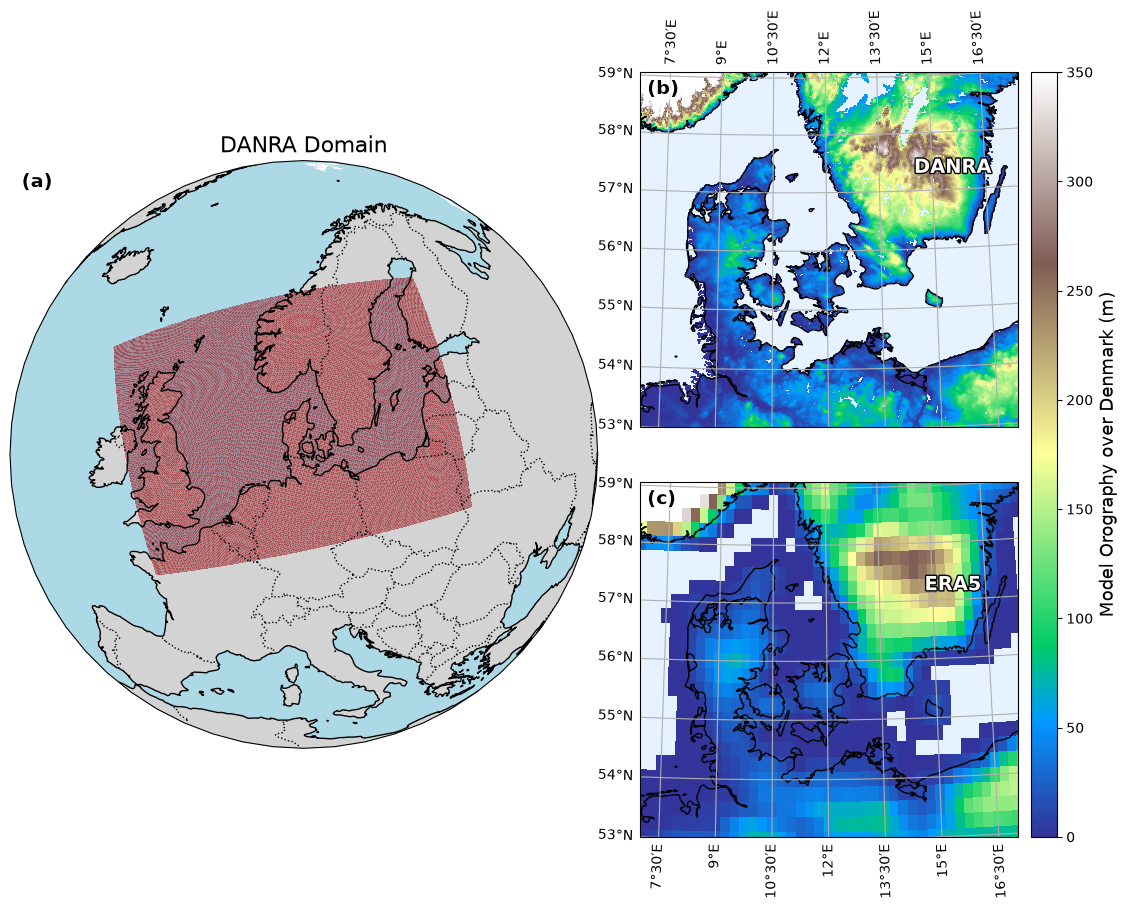

In [5]:
# Plot orography for DANRA and ERA5 datasets with bounding boxes in new layout

orog = ds_danra_sl.surface_geopotential / 9.82  # Convert to meters
orog = orog.where(ds_danra_sl.lsm != 0)  # Set sea points (lsm == 0) to NaN
lat = ds_danra_sl.lat
lon = ds_danra_sl.lon
era_orog = era5_geopotential / 9.82  # Convert to meters
era5_orog = era_orog.where(era5_lsm != 0)

fig = plt.figure(figsize=(13, 10.4))
gs = fig.add_gridspec(2, 5, wspace=0.25, hspace=0.05)

# Globe subplot (left, spans both rows)
ax_globe = fig.add_subplot(
    gs[:, 0:3],
    projection=ccrs.NearsidePerspective(
        central_latitude=55,
        central_longitude=10,
        satellite_height=8.5e5
    )
)
ax_globe.set_global()
ax_globe.coastlines()
ax_globe.set_title("DANRA Domain", fontsize=16)

ax_globe.text(
    0.02, 0.98, "(a)", transform=ax_globe.transAxes,
    fontsize=14, fontweight="bold", va="top", ha="left",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1)
)

# Draw DANRA domain
ax_globe.add_feature(cfeature.BORDERS, linestyle=':')
ax_globe.add_feature(cfeature.LAND, facecolor='lightgray')
ax_globe.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax_globe.pcolormesh(
    lon, lat, np.ones_like(ds_danra_sl.lsm),
    transform=ccrs.PlateCarree(),
    cmap='Reds',
    vmin=0, vmax=1.1,
    alpha=0.4
)
plot_bbox = [7, 53, 17, 59]  # [min_lon, min_lat, max_lon, max_lat]

# ERA5 orography subplot (top right)
ax_danra = fig.add_subplot(
    gs[0, 3:],
    projection=ccrs.AlbersEqualArea(
        central_longitude=11.0,
        central_latitude=55.0
    )
)
ax_danra.set_facecolor("#e6f2ff")
mesh1 = ax_danra.pcolormesh(
    lon, lat, orog.squeeze(),
    transform=ccrs.PlateCarree(),
    cmap="terrain",
    vmin=0,
    vmax=350,
    rasterized=True
)
ax_danra.coastlines()
ax_danra.set_extent([7, 17, 53, 59], crs=ccrs.PlateCarree())
gl1 = ax_danra.gridlines(
    draw_labels=True,
    dms=True,
    x_inline=False,
    y_inline=False
)
gl1.top_labels = True
gl1.bottom_labels = False
gl1.left_labels = True
gl1.right_labels = False

# DANRA orography subplot (bottom right)
ax_era5 = fig.add_subplot(
    gs[1, 3:],
    projection=ccrs.AlbersEqualArea(
        central_longitude=11.0,
        central_latitude=55.0
    )
)
ax_era5.set_facecolor("#e6f2ff")
mesh0 = ax_era5.pcolormesh(
    era5_lon, era5_lat, era5_orog.values,
    transform=ccrs.PlateCarree(),
    cmap="terrain",
    vmin=0,
    vmax=350,
    rasterized=True
)
ax_era5.coastlines()
ax_era5.set_extent(
    [7, 17, 53, 59], crs=ccrs.PlateCarree()
)
gl0 = ax_era5.gridlines(
    draw_labels=True, dms=True, x_inline=False, y_inline=False
)
gl0.top_labels = False
gl0.bottom_labels = True
gl0.left_labels = True
gl0.right_labels = False

# Create an axis for the colorbar that spans both right subplots
cbar_ax = fig.add_axes([
    0.91,
    ax_era5.get_position().y0,
    0.02,
    ax_danra.get_position().y1 - ax_era5.get_position().y0
])
cbar = fig.colorbar(mesh1, cax=cbar_ax, orientation='vertical')
cbar.set_label("Model Orography over Denmark (m)", fontsize=13)

ax_era5.text(
    0.02, 0.98, "(c)", transform=ax_era5.transAxes,
    fontsize=14, fontweight="bold", va="top", ha="left",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1)
)
ax_danra.text(
    0.02, 0.98, "(b)", transform=ax_danra.transAxes,
    fontsize=14, fontweight="bold", va="top", ha="left",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1)
)


fig.text(
    0.85,
    0.36,
    "ERA5",
    color="white",
    fontsize=14,
    ha="center",
    va="bottom",
    fontweight="bold",
    path_effects=[patheffects.withStroke(linewidth=2, foreground="black")],
)

fig.text(
    0.85,
    0.78,
    "DANRA",
    color="white",
    fontsize=14,
    ha="center",
    va="top",
    fontweight="bold",
    path_effects=[patheffects.withStroke(linewidth=2, foreground="black")],
)

plt.show()


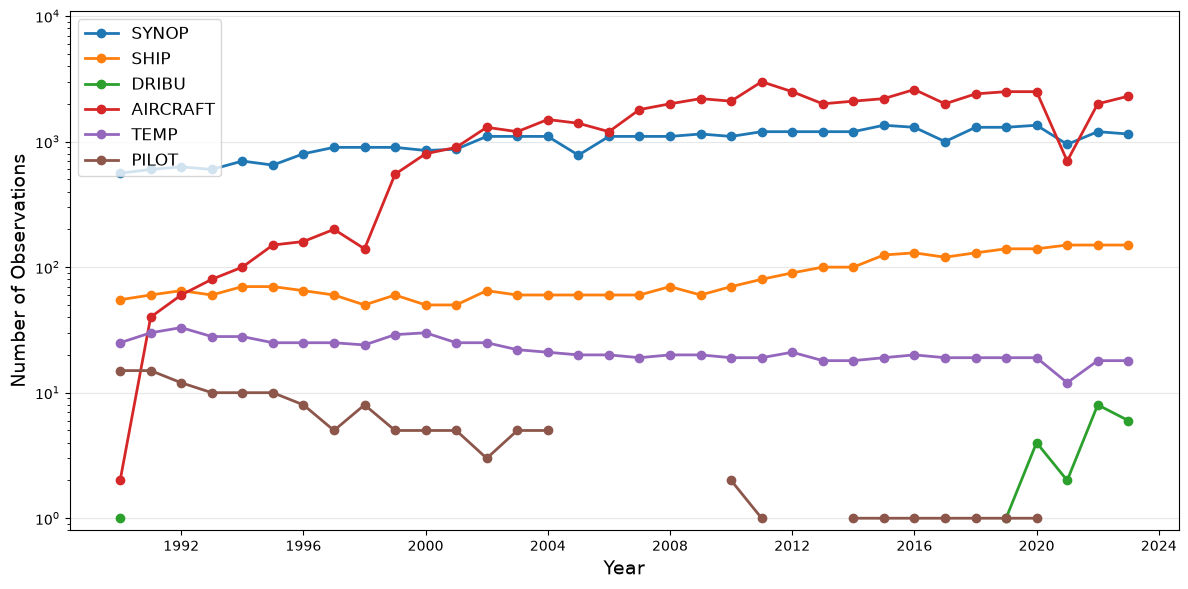

In [6]:
# Read the CSV file
df = pd.read_csv('danra_obsusage.csv')
df.replace(0, np.nan, inplace=True)

# Convert YEAR column to datetime (format YYYY01)
df['YEAR'] = pd.to_datetime(df['YEAR'], format='%Y%m')

# Sort by time
df = df.sort_values('YEAR')

# Create the plot
fig, ax = plt.subplots(figsize=(12, 6))

# Plot each observation type
for col in df.columns[1:]:  # Skip the YEAR column
    ax.plot(df['YEAR'], df[col], marker='o', label=col, linewidth=2)

ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Number of Observations', fontsize=14)
ax.legend(loc='upper left', fontsize=12)
ax.set_yscale('log')
ax.set_ylim([0.8, 11000])
ax.set_yticks([1, 10, 100, 1000, 10000])
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()